# Heart Disease Prediction

This noebook goes through the exploratory data analysis of the Heart Disease UCI. The version of this datset used in thie notebook is linked [here](https://gist.github.com/notreallyme2/8d20f6b5bcc3606e0541cbdf2ee0a7a6). This is the first notebook for this 'lab' assignment.

Task have been provided my ChatGPT, the answers are my own.

## Task 04 - Baseline Model: Logistic Regression

In `02_modeling.ipynb`:

1. Train/test split (test 20%, random_state=42)

2. Pipeline:
    - preprocess steps
    - logistic regression (`class_weight='balanced'`, `max_iter=2000`)

3. Evaluate:
    - Accuracy
    - Precision
    - Recall
    - F1
    - ROC-AUC
    - Confusion matrix
    - ROC curve plot

Interpretation questions:
- Is recall good enough for medical screening?
- What trade-offs do you see?

Deliverable: metrics + ROC curve + 3–4 bullet interpretations.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
data_path = "../data/heart.csv"
df = pd.read_csv(data_path)
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [3]:
import sys
import os
sys.path.append(os.path.abspath(".."))
from src.preprocess import preprocess

In [4]:
X, y, preprocessor = preprocess(df)
X, y, preprocessor

(     age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
 0     63    1   3       145   233    1        0      150      0      2.3   
 1     37    1   2       130   250    0        1      187      0      3.5   
 2     41    0   1       130   204    0        0      172      0      1.4   
 3     56    1   1       120   236    0        1      178      0      0.8   
 4     57    0   0       120   354    0        1      163      1      0.6   
 ..   ...  ...  ..       ...   ...  ...      ...      ...    ...      ...   
 298   57    0   0       140   241    0        1      123      1      0.2   
 299   45    1   3       110   264    0        1      132      0      1.2   
 300   68    1   0       144   193    1        1      141      0      3.4   
 301   57    1   0       130   131    0        1      115      1      1.2   
 302   57    0   1       130   236    0        0      174      0      0.0   
 
      slope  ca  thal  
 0        0   0     1  
 1        0   0     2  
 2

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
X_train

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
132,42,1,1,120,295,0,1,162,0,0.0,2,0,2
202,58,1,0,150,270,0,0,111,1,0.8,2,0,3
196,46,1,2,150,231,0,1,147,0,3.6,1,0,2
75,55,0,1,135,250,0,0,161,0,1.4,1,0,2
176,60,1,0,117,230,1,1,160,1,1.4,2,2,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...
188,50,1,2,140,233,0,1,163,0,0.6,1,1,3
71,51,1,2,94,227,0,1,154,1,0.0,2,1,3
106,69,1,3,160,234,1,0,131,0,0.1,1,1,2
270,46,1,0,120,249,0,0,144,0,0.8,2,0,3


In [7]:
X_test

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
179,57,1,0,150,276,0,0,112,1,0.6,1,1,1
228,59,1,3,170,288,0,0,159,0,0.2,1,0,3
111,57,1,2,150,126,1,1,173,0,0.2,2,1,3
246,56,0,0,134,409,0,0,150,1,1.9,1,2,3
60,71,0,2,110,265,1,0,130,0,0.0,2,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
249,69,1,2,140,254,0,0,146,0,2.0,1,3,3
104,50,1,2,129,196,0,1,163,0,0.0,2,0,2
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3
193,60,1,0,145,282,0,0,142,1,2.8,1,2,3


In [8]:
y_train

132    1
202    0
196    0
75     1
176    0
      ..
188    0
71     1
106    1
270    0
102    1
Name: target, Length: 242, dtype: int64

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=2000))
])

In [10]:
model_lr.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [11]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, RocCurveDisplay

In [12]:
def get_prediction_report(y_true, y_pred, y_proba):
    print("Classification Report:")
    print(classification_report(y_true, y_pred))
    print(f'ROC-AUC Score: {roc_auc_score(y_true, y_proba)}')
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

In [13]:
preds_lr = model_lr.predict(X_test)
preds_lr

array([0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0])

In [14]:
y_pred_proba = model_lr.predict_proba(X_test)[:, 1]
y_pred_proba

array([0.01265098, 0.47339677, 0.62527   , 0.01020055, 0.9479589 ,
       0.93157192, 0.58049119, 0.00235694, 0.00475153, 0.42233309,
       0.50458788, 0.1091185 , 0.93224347, 0.03967808, 0.99009855,
       0.95036316, 0.98351191, 0.02247973, 0.00260924, 0.00695257,
       0.46383345, 0.05808013, 0.32914137, 0.69842213, 0.78267526,
       0.5600434 , 0.89827251, 0.63426467, 0.01742153, 0.95483151,
       0.01261226, 0.01583616, 0.00401127, 0.12856281, 0.88586966,
       0.01922492, 0.76934835, 0.82519835, 0.67520243, 0.86125963,
       0.93682308, 0.84390166, 0.93304381, 0.69179349, 0.82277906,
       0.06729473, 0.32567485, 0.9700926 , 0.02219923, 0.00487345,
       0.04548433, 0.012646  , 0.66381446, 0.95699745, 0.09969279,
       0.00938564, 0.08688743, 0.97081065, 0.00996288, 0.00169831,
       0.03878366])

In [15]:
get_prediction_report(y_test, preds_lr, y_pred_proba)

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.93      0.89        29
           1       0.93      0.84      0.89        32

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

ROC-AUC Score: 0.9450431034482758
Confusion Matrix:
[[27  2]
 [ 5 27]]


We have an excellent recall for target class `0` of about `93%`. \
For target class `1`, the recall is also almost as good but still about `10%` lower than class `0` at `84%`. \
I don't see a big trade off, but I assume for a medical classifier, we'd want to maximize the recall for class `1`, so we don't miss someone that *has* heart disease, because the consequences could be fatal for the patient. \
The ROC-AUC score is very promising at `0.95`.

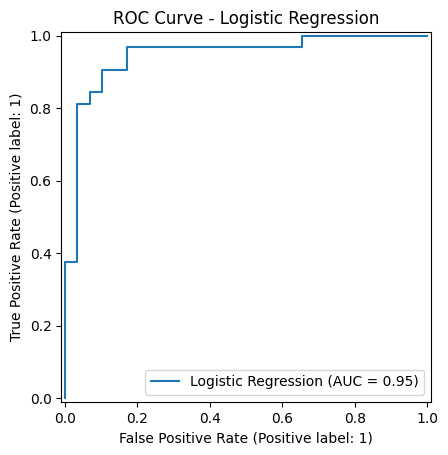

In [16]:
RocCurveDisplay.from_predictions(
    y_test,
    y_pred_proba,
    name="Logistic Regression",
)

plt.title("ROC Curve - Logistic Regression")
plt.show()

## Task 05 — Try Two More Models
### Required models:

1. SVM (LinearSVC or SVC with RBF kernel)
    - Use `class_weight='balanced'`
2. Random Forest
    - Keep it small (`n_estimators=100`, `max_depth=5–10`)

### Optional (bonus):

`XGBoost` or `GradientBoostingClassifier`

### For each model:
- Use pipeline + appropriate scaler
- Fit
- Evaluate (same metrics as baseline)
- Record results in a small comparison table

**Deliverable**: a comparison table:

| **Model**             | **Accuracy**  | **Recall**    | **F1**    | **ROC-AUC**   |
| --------------------- | ------------- | ------------- | --------- | ------------- |
| Logistic Regression   | ?             | ?             | ?         | ?             |
| SVM                   | ?             | ?             | ?         | ?             |
| Random Forest         | ?             | ?             | ?         | ?             |

In [17]:
from sklearn.svm import SVC

In [18]:
model_svc = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='rbf', class_weight='balanced', probability=True))
])

In [19]:
model_svc.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [20]:
preds_svc = model_svc.predict(X_test)
y_pred_proba_svc = model_svc.predict_proba(X_test)[:, 1]

In [21]:
get_prediction_report(y_test, preds_svc, y_pred_proba_svc)

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.93      0.89        29
           1       0.93      0.84      0.89        32

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

ROC-AUC Score: 0.9342672413793103
Confusion Matrix:
[[27  2]
 [ 5 27]]


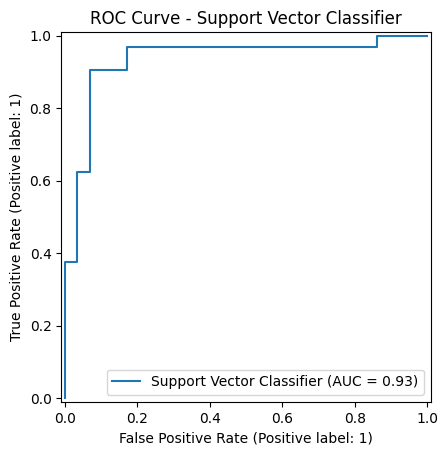

In [22]:
RocCurveDisplay.from_predictions(
    y_test,
    y_pred_proba_svc,
    name="Support Vector Classifier",
)

plt.title("ROC Curve - Support Vector Classifier")
plt.show()

In [23]:
from sklearn.ensemble import RandomForestClassifier

In [24]:
model_rfc = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, max_depth=5, n_jobs=-1, random_state=42))
])

In [25]:
model_rfc.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [26]:
preds_rfc = model_rfc.predict(X_test)
y_pred_proba_rfc = model_rfc.predict_proba(X_test)[:, 1]

In [27]:
get_prediction_report(y_test, preds_rfc, y_pred_proba_rfc)

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.86      0.88        29
           1       0.88      0.91      0.89        32

    accuracy                           0.89        61
   macro avg       0.89      0.88      0.88        61
weighted avg       0.89      0.89      0.89        61

ROC-AUC Score: 0.9385775862068966
Confusion Matrix:
[[25  4]
 [ 3 29]]


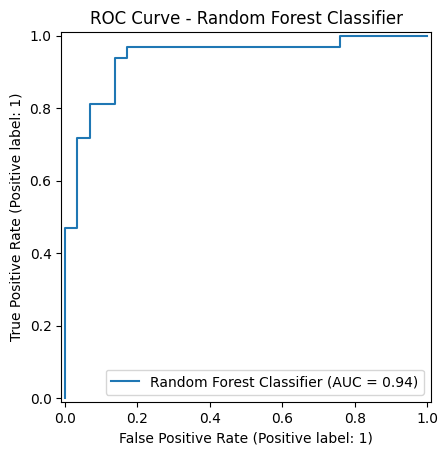

In [28]:
RocCurveDisplay.from_predictions(
    y_test,
    y_pred_proba_rfc,
    name="Random Forest Classifier",
)

plt.title("ROC Curve - Random Forest Classifier")
plt.show()

Similar `recall` for target class `1` for Logistic Regression and  Support Vector Classifier of `0.84`. Random forest does a better job, having a `recall` of `0.91`.

| **Model**             | **Accuracy**  | **Recall**    | **F1**    | **ROC-AUC**   |
| --------------------- | ------------- | ------------- | --------- | ------------- |
| Logistic Regression   | 0.89          | 0.89          | 0.89      | 0.95          |
| SVC                   | 0.89          | 0.89          | 0.89      | 0.93          |
| Random Forest         | 0.89          | 0.89          | 0.89      | 0.94          |

## Task 06 - Advanced Evaluation: Precision–Recall Curve

### Steps:

1. Plot precision-recall curve for your best model.
2. Compute “optimal threshold” using one of:
    - maximizing F1
    - maximizing recall at precision > 0.7
    - or based on business need
3. Recompute confusion matrix at this optimal threshold.

### Interpretation:
- Why is threshold tuning important in medicine?
- Which patients are misclassified after tuning?

**Deliverable**: PR curve + threshold selection + explanation.

Here, I'm choosing `Logistic Regression` as the *best model* to continue with because it has similar `weighted recall` to the other models, while achieving the best `ROC score`. \
While `Random Forests` achieved the highest recall for specifically the positive target class, the `logistic regression` model is still using an unoptimized threshold of `0.5`.\
Also, better interpretability of the `logistic regression` model, makes it more suitable for medical prediction tasks.

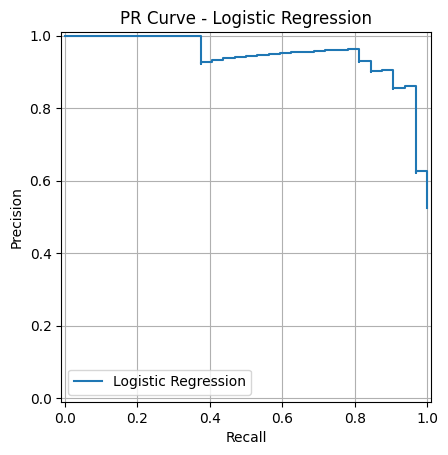

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay, precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba)

disp = PrecisionRecallDisplay(precisions, recalls)
disp.plot(name = "Logistic Regression")

plt.title("PR Curve - Logistic Regression")
plt.grid(True)
plt.show()

In [30]:
from sklearn.metrics import f1_score

f1_scores = []

for t in thresholds:
    y_pred_t = (y_pred_proba >= t).astype(int)
    f1 = f1_score(y_test, y_pred_t)
    f1_scores.append(f1)

In [31]:
import numpy as np
best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print(f"Best Threshold: {best_threshold}")
print(f"Best F1: {f1_scores[best_index]}")

Best Threshold: 0.10911849721631603
Best F1: 0.9117647058823529


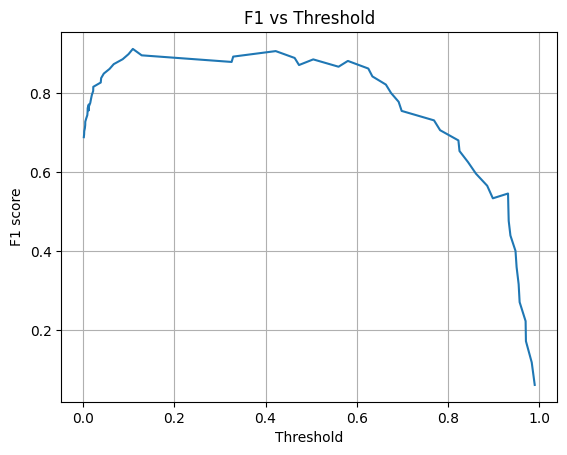

In [32]:
plt.plot(thresholds, f1_scores)
plt.xlabel("Threshold")
plt.ylabel("F1 score")
plt.title("F1 vs Threshold")
plt.grid(True)
plt.show()

In [33]:
best_y_preds = (y_pred_proba >= best_threshold).astype(int)

print("Optimized Classification Report")
print(classification_report(y_test, best_y_preds))
print("Optimized Confusion Matrix")
print(confusion_matrix(y_test, best_y_preds))

Optimized Classification Report
              precision    recall  f1-score   support

           0       0.96      0.83      0.89        29
           1       0.86      0.97      0.91        32

    accuracy                           0.90        61
   macro avg       0.91      0.90      0.90        61
weighted avg       0.91      0.90      0.90        61

Optimized Confusion Matrix
[[24  5]
 [ 1 31]]


We found the optimal probablity threshold to predict the classes to be `0.109`. By default the probability threshold to predict the classes is at `0.5`. We, we are now lowering the bar, and saying more patients may be diseased. \
For the linear model, without threshold tuning, we had a recall of `0.84` for class 1 (patients with disease), so out of `32` unhealthy patients, we were missing out on `5` of those. \
Now, with a tuned model, we have a recall of `0.97` for class 1, and we miss only `1` unhealthy patient! \
In doing so, our precision went down from `0.93` to `0.86` for class 1, meaning we were flagging 2 healthy patients as having the disease, to now flagging 5 healthy patients, but it is an acceptable trade-off for better catching diseased patients. \
Meanwhile, accuracy and f1 score remained more or less similar.

## Task 07 - Explainability

You must do both:
1. Logistic Regression coefficients
    - Extract coefficients
    - Map to feature names
    - Identify features increasing/decreasing risk
2. Random Forest importance (or permutation importance)
    - List top 5 features
    - Compare with logistic regression insights

### Optional:

Use **SHAP** (if you want deeper interpretability)

**Deliverable**: short section interpreting top medical risk factors.

In [41]:
feature_names = model_lr.named_steps['preprocessor'].get_feature_names_out()
feature_names

array(['numeric__age', 'numeric__trestbps', 'numeric__chol',
       'numeric__thalach', 'numeric__oldpeak', 'categorical__sex_0',
       'categorical__sex_1', 'categorical__cp_0', 'categorical__cp_1',
       'categorical__cp_2', 'categorical__cp_3', 'categorical__fbs_0',
       'categorical__fbs_1', 'categorical__restecg_0',
       'categorical__restecg_1', 'categorical__restecg_2',
       'categorical__exang_0', 'categorical__exang_1',
       'categorical__slope_0', 'categorical__slope_1',
       'categorical__slope_2', 'categorical__ca_0', 'categorical__ca_1',
       'categorical__ca_2', 'categorical__ca_3', 'categorical__ca_4',
       'categorical__thal_0', 'categorical__thal_1',
       'categorical__thal_2', 'categorical__thal_3'], dtype=object)

In [35]:
weights = model_lr.named_steps['classifier'].coef_[0]
weights

array([ 0.1293704 , -0.31990241, -0.12601694,  0.29752902, -0.55393164,
        0.69109297, -0.70103443, -1.07692146, -0.2464791 ,  0.54659205,
        0.76686705, -0.23608656,  0.22614509, -0.1730699 ,  0.21857878,
       -0.05545034,  0.44226605, -0.45220751, -0.18397627, -0.50054074,
        0.67457555,  1.40547118, -0.71177705, -1.09513324, -0.33401883,
        0.72551647,  0.0282433 ,  0.27626978,  0.46078701, -0.77524155])

In [38]:
coeff_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": weights
})

coeff_df.sort_values(by="coefficient", ascending=False)

,feature,coefficient
21,categorical__ca_0,1.405471
10,categorical__cp_3,0.766867
25,categorical__ca_4,0.725516
5,categorical__sex_0,0.691093
20,categorical__slope_2,0.674576
9,categorical__cp_2,0.546592
28,categorical__thal_2,0.460787
16,categorical__exang_0,0.442266
3,numeric__thalach,0.297529
27,categorical__thal_1,0.276270


According to these coefficients, `ca` of class 0 & 4, and `cp` of class 3 are the biggest positive features indicating heart disease. Also, `ca` of class 2 and `cp` of class 0 are the biggest negative features.

In [ ]:
weights_rf = model_rfc.named_steps['classifier'].feature_importances_

array(['numeric__age', 'numeric__trestbps', 'numeric__chol',
       'numeric__thalach', 'numeric__oldpeak', 'categorical__sex_0',
       'categorical__sex_1', 'categorical__cp_0', 'categorical__cp_1',
       'categorical__cp_2', 'categorical__cp_3', 'categorical__fbs_0',
       'categorical__fbs_1', 'categorical__restecg_0',
       'categorical__restecg_1', 'categorical__restecg_2',
       'categorical__exang_0', 'categorical__exang_1',
       'categorical__slope_0', 'categorical__slope_1',
       'categorical__slope_2', 'categorical__ca_0', 'categorical__ca_1',
       'categorical__ca_2', 'categorical__ca_3', 'categorical__ca_4',
       'categorical__thal_0', 'categorical__thal_1',
       'categorical__thal_2', 'categorical__thal_3'], dtype=object)

In [43]:
importance_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": weights_rf
})

importance_df.sort_values(by="coefficient", ascending=False).head()

,feature,coefficient
28,categorical__thal_2,0.108400
4,numeric__oldpeak,0.096736
7,categorical__cp_0,0.092650
21,categorical__ca_0,0.083111
3,numeric__thalach,0.077159


According to the random forest model, `thal` of class 2, `oldpeak`, `cp` pf class 0, `ca` of class 0, and `thalach` are the most important features for predicting heart disease.

## Task 08 - Error Analysis

1. Look at **false negatives** (patients predicted healthy but actually not).
2. Look at **false positives**.
3. Describe:
    - Any patterns?
    - Do certain feature ranges dominate?
4. Suggest **2 improvements** you’d try next:
    - better threshold tuning
    - feature interactions
    - polynomial features
    - grouping ages
    - using clinical domain rules

**Deliverable**: bullet list of findings.

In [44]:
test_results = X_test.copy()
test_results

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
179,57,1,0,150,276,0,0,112,1,0.6,1,1,1
228,59,1,3,170,288,0,0,159,0,0.2,1,0,3
111,57,1,2,150,126,1,1,173,0,0.2,2,1,3
246,56,0,0,134,409,0,0,150,1,1.9,1,2,3
60,71,0,2,110,265,1,0,130,0,0.0,2,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
249,69,1,2,140,254,0,0,146,0,2.0,1,3,3
104,50,1,2,129,196,0,1,163,0,0.0,2,0,2
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3
193,60,1,0,145,282,0,0,142,1,2.8,1,2,3


In [45]:
test_results['y_true'] = y_test
test_results['y_pred'] = best_y_preds
test_results['y_proba'] = y_pred_proba

In [46]:
test_results

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,y_true,y_pred,y_proba
179,57,1,0,150,276,0,0,112,1,0.6,1,1,1,0,0,0.012651
228,59,1,3,170,288,0,0,159,0,0.2,1,0,3,0,1,0.473397
111,57,1,2,150,126,1,1,173,0,0.2,2,1,3,1,1,0.625270
246,56,0,0,134,409,0,0,150,1,1.9,1,2,3,0,0,0.010201
60,71,0,2,110,265,1,0,130,0,0.0,2,1,2,1,1,0.947959
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249,69,1,2,140,254,0,0,146,0,2.0,1,3,3,0,0,0.086887
104,50,1,2,129,196,0,1,163,0,0.0,2,0,2,1,1,0.970811
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0,0,0.009963
193,60,1,0,145,282,0,0,142,1,2.8,1,2,3,0,0,0.001698


In [47]:
fp = test_results[(test_results['y_true'] == 0) & test_results['y_pred'] == 1]
fp

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,y_true,y_pred,y_proba
228,59,1,3,170,288,0,0,159,0,0.2,1,0,3,0,1,0.473397
272,67,1,0,120,237,0,1,71,0,1.0,1,0,2,0,1,0.329141
283,40,1,0,152,223,0,1,181,0,0.0,2,0,3,0,1,0.560043
254,59,1,3,160,273,0,0,125,0,0.0,2,0,2,0,1,0.898273
281,52,1,0,128,204,1,1,156,1,1.0,1,0,0,0,1,0.325675


In [58]:
fn = test_results[(test_results['y_true'] == 1) & (test_results['y_pred'] == 0)]
tp = test_results[(test_results['y_true'] == 1) & (test_results['y_pred'] == 1)]
tn = test_results[(test_results['y_true'] == 0) & (test_results['y_pred'] == 0)]

In [60]:
fn.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,y_true,y_pred,y_proba
count,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000000
mean,64.0,1.0,0.0,128.0,263.0,0.0,1.0,105.0,1.0,0.2,1.0,1.0,3.0,1.0,0.0,0.012612
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,64.0,1.0,0.0,128.0,263.0,0.0,1.0,105.0,1.0,0.2,1.0,1.0,3.0,1.0,0.0,0.012612
25%,64.0,1.0,0.0,128.0,263.0,0.0,1.0,105.0,1.0,0.2,1.0,1.0,3.0,1.0,0.0,0.012612
50%,64.0,1.0,0.0,128.0,263.0,0.0,1.0,105.0,1.0,0.2,1.0,1.0,3.0,1.0,0.0,0.012612
75%,64.0,1.0,0.0,128.0,263.0,0.0,1.0,105.0,1.0,0.2,1.0,1.0,3.0,1.0,0.0,0.012612
max,64.0,1.0,0.0,128.0,263.0,0.0,1.0,105.0,1.0,0.2,1.0,1.0,3.0,1.0,0.0,0.012612


In [61]:
tp.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,y_true,y_pred,y_proba
count,31.000000,31.000000,31.000000,31.000000,31.000000,31.000000,31.000000,31.000000,31.000000,31.000000,31.000000,31.000000,31.000000,31.0,31.0,31.000000
mean,52.032258,0.709677,1.451613,131.612903,233.580645,0.193548,0.580645,161.935484,0.161290,0.661290,1.548387,0.419355,2.096774,1.0,1.0,0.756357
std,9.130476,0.461414,0.960511,18.501671,42.021244,0.401610,0.501610,18.031335,0.373878,1.091078,0.675214,0.885972,0.472923,0.0,0.0,0.236788
min,34.000000,0.000000,0.000000,102.000000,126.000000,0.000000,0.000000,114.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.0,1.0,0.109118
25%,45.000000,0.000000,1.000000,119.000000,206.500000,0.000000,0.000000,150.500000,0.000000,0.000000,1.000000,0.000000,2.000000,1.0,1.0,0.649040
50%,51.000000,1.000000,2.000000,129.000000,227.000000,0.000000,1.000000,164.000000,0.000000,0.000000,2.000000,0.000000,2.000000,1.0,1.0,0.825198
75%,58.000000,1.000000,2.000000,140.000000,260.500000,0.000000,1.000000,173.500000,0.000000,0.650000,2.000000,0.500000,2.000000,1.0,1.0,0.942391
max,71.000000,1.000000,3.000000,178.000000,325.000000,1.000000,1.000000,192.000000,1.000000,4.200000,2.000000,4.000000,3.000000,1.0,1.0,0.990099


In [59]:
fp.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,y_true,y_pred,y_proba
count,5.000000,5.0,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.0,5.000000,5.0,5.0,5.000000
mean,55.400000,1.0,1.200000,146.000000,245.000000,0.200000,0.600000,138.400000,0.200000,0.440000,1.400000,0.0,2.000000,0.0,1.0,0.517306
std,10.114346,0.0,1.643168,21.260292,34.864022,0.447214,0.547723,42.635666,0.447214,0.517687,0.547723,0.0,1.224745,0.0,0.0,0.235063
min,40.000000,1.0,0.000000,120.000000,204.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.0,0.000000,0.0,1.0,0.325675
25%,52.000000,1.0,0.000000,128.000000,223.000000,0.000000,0.000000,125.000000,0.000000,0.000000,1.000000,0.0,2.000000,0.0,1.0,0.329141
50%,59.000000,1.0,0.000000,152.000000,237.000000,0.000000,1.000000,156.000000,0.000000,0.200000,1.000000,0.0,2.000000,0.0,1.0,0.473397
75%,59.000000,1.0,3.000000,160.000000,273.000000,0.000000,1.000000,159.000000,0.000000,1.000000,2.000000,0.0,3.000000,0.0,1.0,0.560043
max,67.000000,1.0,3.000000,170.000000,288.000000,1.000000,1.000000,181.000000,1.000000,1.000000,2.000000,0.0,3.000000,0.0,1.0,0.898273


In [62]:
tn.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,y_true,y_pred,y_proba
count,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.0,24.0,24.000000
mean,55.791667,0.833333,0.083333,141.541667,256.375000,0.291667,0.166667,133.250000,0.666667,1.954167,1.000000,1.750000,2.750000,0.0,0.0,0.025632
std,7.413144,0.380693,0.408248,19.522516,56.684338,0.464306,0.380693,17.686276,0.481543,1.477065,0.510754,1.032094,0.607919,0.0,0.0,0.027528
min,40.000000,0.000000,0.000000,110.000000,164.000000,0.000000,0.000000,99.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.0,0.0,0.001698
25%,53.000000,1.000000,0.000000,130.000000,220.500000,0.000000,0.000000,119.000000,0.000000,0.950000,1.000000,1.000000,3.000000,0.0,0.0,0.006433
50%,56.500000,1.000000,0.000000,140.000000,261.500000,0.000000,0.000000,139.500000,1.000000,1.850000,1.000000,2.000000,3.000000,0.0,0.0,0.014244
75%,61.000000,1.000000,0.000000,150.000000,288.250000,1.000000,0.000000,146.000000,1.000000,2.800000,1.000000,2.000000,3.000000,0.0,0.0,0.039007
max,69.000000,1.000000,2.000000,200.000000,409.000000,1.000000,1.000000,171.000000,1.000000,6.200000,2.000000,4.000000,3.000000,0.0,0.0,0.099693


### Findings (False Negative)
- The `age` of the only false negative is higher than the average `age` of the true positives.
- The `chol` of the false negative is also higher than the average `chol` of true positives, in fact, it seem to be even higher than the average value for true negatives, which might explain why it was flagged as negative.
- The same can also be said about `thalach` and `oldpeak`.
- The `probability` of the false negative (approx 0.013) is also much lower than the threshold value (approx 0.109)

### Findings (False Positives)
- False positives and true negatives seem to have similar average `age`.
- The average `trestbps` for false positives seem to be higher than for true negatives, this may be a reason for the falsely flagged.
- Similarly, average `thalach` and `restecg`for the false positives are higher and true negatives, with average `restecg` for false positives and true positives being very close in value.
- False positives also have lower average `oldpeak` than the true negatives, another possible reason.

### Possible Improvements
- Lower decision threshold to increase recall and reduce clinically dangerous false negatives
- Evaluate non-linear models (Random Forest / Gradient Boosting) to better capture interactions such as age × thalach and chol × ECG patterns
- Add clinically meaningful feature engineering since misclassifications mostly occur in borderline clinical cases